In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Finds the folder used by your notebook.
DATA_DIRECTORY = next(
    (
        path
        for path in [
            Path("../geo_us"),
            Path("data/geo_us"),
            Path("upload"),
        ]
        if path.exists()
    ),
    None,
)

if DATA_DIRECTORY is None:
    raise FileNotFoundError("Could not find data/geo_us or upload.")

# Your normal filename. The fallback below also handles copied files with (1), (2), etc.
HISTORY_FILENAME = "gp_history_20260801_20260901_3cbd5060be.json"
HISTORY_PATH = DATA_DIRECTORY / HISTORY_FILENAME

if not HISTORY_PATH.exists():
    history_candidates = sorted(
        DATA_DIRECTORY.glob("gp_history_*.json"),
        key=lambda path: path.stat().st_mtime,
    )
    if not history_candidates:
        raise FileNotFoundError("No gp_history_*.json file found.")
    HISTORY_PATH = history_candidates[-1]

# Constants
MU_EARTH_KM3_S2 = 398_600.4418

# Screening settings — conservative starting values, not calibrated truth.
MIN_STEP_HOURS = 2.0
MAX_STEP_HOURS = 24.0
ROBUST_Z_THRESHOLD = 10.0
MIN_AI_DV_PROXY_M_S = 0.25
EVENT_MERGE_GAP_HOURS = 18.0

# Minimum data needed before we interpret a satellite's behavior.
MIN_OBSERVED_DAYS = 21.0
MIN_USABLE_STEPS = 20

print(f"Using history file: {HISTORY_PATH.resolve()}")

Using history file: C:\Users\leo.langou\OneDrive - West Point\Desktop\2027 AY-1\MA498\Space_Logistics\data\geo_us\gp_history_20260801_20260901_3cbd5060be.json


In [3]:
with HISTORY_PATH.open(encoding="utf-8") as file:
    payload = json.load(file)

records = (
    payload
    if isinstance(payload, list)
    else payload.get("data", payload.get("items", []))
)

history = pd.DataFrame(records)

required_columns = {
    "NORAD_CAT_ID",
    "OBJECT_NAME",
    "EPOCH",
    "CREATION_DATE",
    "MEAN_MOTION",
    "ECCENTRICITY",
    "INCLINATION",
}

missing_columns = required_columns - set(history.columns)
if missing_columns:
    raise ValueError(f"History file is missing: {sorted(missing_columns)}")

history["NORAD_CAT_ID"] = history["NORAD_CAT_ID"].astype(str)

for column in ["EPOCH", "CREATION_DATE"]:
    history[column] = pd.to_datetime(
        history[column],
        utc=True,
        errors="coerce",
    )

for column in ["MEAN_MOTION", "ECCENTRICITY", "INCLINATION"]:
    history[column] = pd.to_numeric(history[column], errors="coerce")

# Keep one public element set per object and epoch.
history = (
    history
    .dropna(
        subset=[
            "NORAD_CAT_ID",
            "OBJECT_NAME",
            "EPOCH",
            "MEAN_MOTION",
            "ECCENTRICITY",
            "INCLINATION",
        ]
    )
    .query("MEAN_MOTION > 0")
    .sort_values(["NORAD_CAT_ID", "EPOCH", "CREATION_DATE"])
    .drop_duplicates(["NORAD_CAT_ID", "EPOCH"], keep="last")
    .reset_index(drop=True)
)

# Mean motion -> semimajor axis
mean_motion_rad_s = 2.0 * np.pi * history["MEAN_MOTION"] / 86_400.0

history["SEMI_MAJOR_AXIS_KM"] = (
    MU_EARTH_KM3_S2 / mean_motion_rad_s**2
) ** (1.0 / 3.0)

history["CIRCULAR_SPEED_KM_S"] = np.sqrt(
    MU_EARTH_KM3_S2 / history["SEMI_MAJOR_AXIS_KM"]
)

print(f"Objects: {history['NORAD_CAT_ID'].nunique()}")
print(f"Cleaned public element sets: {len(history):,}")
print(f"History window: {history['EPOCH'].min()} to {history['EPOCH'].max()}")

Objects: 102
Cleaned public element sets: 11,395
History window: 2026-07-25 00:38:50.860320+00:00 to 2026-09-03 20:48:38.536416+00:00


In [4]:
# Do NOT calculate |v(t2) - v(t1)|.
# Those states occur at different places in the orbit.
#
# Instead, use changes in mean semimajor axis, inclination, and eccentricity.

steps = (
    history
    .sort_values(["NORAD_CAT_ID", "EPOCH"])
    .reset_index(drop=True)
    .copy()
)

grouped = steps.groupby("NORAD_CAT_ID", sort=False)

steps["STEP_HOURS"] = (
    grouped["EPOCH"].diff().dt.total_seconds() / 3600.0
)

steps["DELTA_A_KM"] = grouped["SEMI_MAJOR_AXIS_KM"].diff()
steps["DELTA_I_RAD"] = np.deg2rad(grouped["INCLINATION"].diff())
steps["DELTA_E"] = grouped["ECCENTRICITY"].diff()

# Small-change approximations:
# Δv_a ≈ (v / 2) * |Δa / a|
# Δv_i ≈ v * |Δi|
#
# This is an element-change Δv PROXY, not a measured maneuver Δv.
steps["DV_A_PROXY_M_S"] = (
    0.5
    * steps["CIRCULAR_SPEED_KM_S"]
    * steps["DELTA_A_KM"].abs()
    / steps["SEMI_MAJOR_AXIS_KM"]
    * 1000.0
)

steps["DV_I_PROXY_M_S"] = (
    steps["CIRCULAR_SPEED_KM_S"]
    * steps["DELTA_I_RAD"].abs()
    * 1000.0
)

steps["AI_DV_PROXY_M_S"] = np.hypot(
    steps["DV_A_PROXY_M_S"],
    steps["DV_I_PROXY_M_S"],
)

# Exclude duplicate/near-duplicate updates and long unobserved gaps.
usable_steps = steps.loc[
    steps["STEP_HOURS"].between(MIN_STEP_HOURS, MAX_STEP_HOURS)
].copy()


def robust_positive_z(frame, column):
    """Object-specific robust anomaly score for an absolute element change."""
    values = frame[column].abs()

    median = values.groupby(frame["NORAD_CAT_ID"]).transform("median")
    mad = values.groupby(frame["NORAD_CAT_ID"]).transform(
        lambda series: np.median(np.abs(series - np.median(series)))
    )

    robust_scale = 1.4826 * mad
    robust_scale = robust_scale.where(robust_scale > 1e-12)

    return ((values - median) / robust_scale).clip(lower=0).fillna(0.0)


usable_steps["Z_DELTA_A"] = robust_positive_z(
    usable_steps,
    "DELTA_A_KM",
)
usable_steps["Z_DELTA_I"] = robust_positive_z(
    usable_steps,
    "DELTA_I_RAD",
)
usable_steps["Z_DELTA_E"] = robust_positive_z(
    usable_steps,
    "DELTA_E",
)

usable_steps["MANEUVER_ANOMALY_SCORE"] = np.sqrt(
    usable_steps["Z_DELTA_A"] ** 2
    + usable_steps["Z_DELTA_I"] ** 2
    + usable_steps["Z_DELTA_E"] ** 2
)

usable_steps["IS_CANDIDATE_CONTROL_EVENT"] = (
    usable_steps["MANEUVER_ANOMALY_SCORE"] >= ROBUST_Z_THRESHOLD
) & (
    usable_steps["AI_DV_PROXY_M_S"] >= MIN_AI_DV_PROXY_M_S
)

print(f"Usable element-to-element steps: {len(usable_steps):,}")
print(
    "Candidate high-anomaly steps:",
    int(usable_steps["IS_CANDIDATE_CONTROL_EVENT"].sum()),
)

Usable element-to-element steps: 8,417
Candidate high-anomaly steps: 241


In [5]:
candidate_steps = (
    usable_steps.loc[
        usable_steps["IS_CANDIDATE_CONTROL_EVENT"]
    ]
    .copy()
    .sort_values(["NORAD_CAT_ID", "EPOCH"])
)

if candidate_steps.empty:
    candidate_events = pd.DataFrame(
        columns=[
            "NORAD_CAT_ID",
            "EVENT_NUMBER",
            "OBJECT_NAME",
            "EVENT_START_UTC",
            "EVENT_END_UTC",
            "N_CANDIDATE_UPDATES",
            "OBSERVED_EVENT_SPAN_HOURS",
            "MAX_AI_DV_PROXY_M_S",
            "MAX_MANEUVER_ANOMALY_SCORE",
        ]
    )
else:
    candidate_steps["HOURS_SINCE_PREVIOUS_CANDIDATE"] = (
        candidate_steps
        .groupby("NORAD_CAT_ID")["EPOCH"]
        .diff()
        .dt.total_seconds()
        / 3600.0
    )

    candidate_steps["STARTS_NEW_EVENT"] = (
        candidate_steps["HOURS_SINCE_PREVIOUS_CANDIDATE"].isna()
        | (
            candidate_steps["HOURS_SINCE_PREVIOUS_CANDIDATE"]
            > EVENT_MERGE_GAP_HOURS
        )
    )

    candidate_steps["EVENT_NUMBER"] = (
        candidate_steps
        .groupby("NORAD_CAT_ID")["STARTS_NEW_EVENT"]
        .cumsum()
        .astype(int)
    )

    candidate_events = (
        candidate_steps
        .groupby(["NORAD_CAT_ID", "EVENT_NUMBER"], as_index=False)
        .agg(
            OBJECT_NAME=("OBJECT_NAME", "last"),
            EVENT_START_UTC=("EPOCH", "min"),
            EVENT_END_UTC=("EPOCH", "max"),
            N_CANDIDATE_UPDATES=("EPOCH", "size"),
            MAX_AI_DV_PROXY_M_S=("AI_DV_PROXY_M_S", "max"),
            MAX_MANEUVER_ANOMALY_SCORE=(
                "MANEUVER_ANOMALY_SCORE",
                "max",
            ),
        )
    )

    candidate_events["OBSERVED_EVENT_SPAN_HOURS"] = (
        candidate_events["EVENT_END_UTC"]
        - candidate_events["EVENT_START_UTC"]
    ).dt.total_seconds() / 3600.0

candidate_events.head()

,NORAD_CAT_ID,EVENT_NUMBER,OBJECT_NAME,EVENT_START_UTC,EVENT_END_UTC,N_CANDIDATE_UPDATES,MAX_AI_DV_PROXY_M_S,MAX_MANEUVER_ANOMALY_SCORE,OBSERVED_EVENT_SPAN_HOURS
0,23467,1,UFO 4 (USA 108),2026-07-31 18:16:24.439008+00:00,2026-07-31 18:16:24.439008+00:00,1,0.708376,91.673859,0.000000
1,23613,1,TDRS 7,2026-08-08 07:30:21.847104+00:00,2026-08-08 07:30:21.847104+00:00,1,2.189403,303.935338,0.000000
2,27875,1,USA 170,2026-08-15 03:25:53.063328+00:00,2026-08-15 20:51:14.115168+00:00,2,0.288664,271.720345,17.422514
3,27875,2,USA 170,2026-09-03 02:29:29.764608+00:00,2026-09-03 16:30:30.123360+00:00,2,0.944445,94.461911,14.016766
4,28117,1,UFO 11 (USA 174),2026-07-29 13:03:19.654272+00:00,2026-07-29 13:03:19.654272+00:00,1,0.564181,629.050230,0.000000


In [6]:
observation_summary = (
    history
    .groupby("NORAD_CAT_ID", as_index=False)
    .agg(
        OBJECT_NAME=("OBJECT_NAME", "last"),
        HISTORY_START_UTC=("EPOCH", "min"),
        HISTORY_END_UTC=("EPOCH", "max"),
        N_PUBLIC_ELEMENT_SETS=("EPOCH", "size"),
    )
)

observation_summary["OBSERVED_DAYS"] = (
    observation_summary["HISTORY_END_UTC"]
    - observation_summary["HISTORY_START_UTC"]
).dt.total_seconds() / 86_400.0

step_summary = (
    usable_steps
    .groupby("NORAD_CAT_ID", as_index=False)
    .agg(
        N_USABLE_STEPS=("EPOCH", "size"),
        MAX_AI_DV_PROXY_M_S=("AI_DV_PROXY_M_S", "max"),
        P95_AI_DV_PROXY_M_S=(
            "AI_DV_PROXY_M_S",
            lambda values: values.quantile(0.95),
        ),
        MAX_MANEUVER_ANOMALY_SCORE=(
            "MANEUVER_ANOMALY_SCORE",
            "max",
        ),
    )
)

event_summary = (
    candidate_events
    .groupby("NORAD_CAT_ID", as_index=False)
    .agg(
        N_CANDIDATE_EVENTS=("EVENT_NUMBER", "nunique"),
        MEDIAN_OBSERVED_EVENT_SPAN_HOURS=(
            "OBSERVED_EVENT_SPAN_HOURS",
            "median",
        ),
        FRACTION_MULTI_UPDATE_EVENTS=(
            "N_CANDIDATE_UPDATES",
            lambda values: (values >= 2).mean(),
        ),
        MAX_EVENT_AI_DV_PROXY_M_S=("MAX_AI_DV_PROXY_M_S", "max"),
    )
)

satellite_features = (
    observation_summary
    .merge(step_summary, on="NORAD_CAT_ID", how="left")
    .merge(event_summary, on="NORAD_CAT_ID", how="left")
)

for column in ["N_USABLE_STEPS", "N_CANDIDATE_EVENTS"]:
    satellite_features[column] = (
        satellite_features[column]
        .fillna(0)
        .astype(int)
    )

for column in [
    "MAX_AI_DV_PROXY_M_S",
    "P95_AI_DV_PROXY_M_S",
    "MAX_MANEUVER_ANOMALY_SCORE",
    "MEDIAN_OBSERVED_EVENT_SPAN_HOURS",
    "FRACTION_MULTI_UPDATE_EVENTS",
    "MAX_EVENT_AI_DV_PROXY_M_S",
]:
    satellite_features[column] = satellite_features[column].fillna(0.0)

satellite_features["EVENTS_PER_30_DAYS"] = (
    30.0
    * satellite_features["N_CANDIDATE_EVENTS"]
    / satellite_features["OBSERVED_DAYS"].replace(0, np.nan)
)

satellite_features["INFERENCE_STATUS"] = np.where(
    (
        satellite_features["OBSERVED_DAYS"] >= MIN_OBSERVED_DAYS
    )
    & (
        satellite_features["N_USABLE_STEPS"] >= MIN_USABLE_STEPS
    ),
    "Behavioral evidence available; propulsion type unconfirmed",
    "Insufficient public-history coverage",
)

abrupt_reference = satellite_features[
    "MAX_EVENT_AI_DV_PROXY_M_S"
].quantile(0.75)


def control_signature(row):
    if row["INFERENCE_STATUS"] != (
        "Behavioral evidence available; propulsion type unconfirmed"
    ):
        return "insufficient history"

    if row["N_CANDIDATE_EVENTS"] == 0:
        return "no high-anomaly control event in window"

    if (
        row["FRACTION_MULTI_UPDATE_EVENTS"] >= 0.50
        and row["MEDIAN_OBSERVED_EVENT_SPAN_HOURS"] >= 6.0
    ):
        return "persistent-control signature"

    if (
        row["FRACTION_MULTI_UPDATE_EVENTS"] <= 0.25
        and row["MAX_EVENT_AI_DV_PROXY_M_S"] >= abrupt_reference
    ):
        return "abrupt-control signature"

    return "mixed / indeterminate control signature"


satellite_features["CONTROL_SIGNATURE"] = satellite_features.apply(
    control_signature,
    axis=1,
)

satellite_features["PROPULSION_TYPE_CONCLUSION"] = (
    "Not identifiable from GP-only history"
)

satellite_features.sort_values(
    "MAX_EVENT_AI_DV_PROXY_M_S",
    ascending=False,
)[
    [
        "NORAD_CAT_ID",
        "OBJECT_NAME",
        "N_CANDIDATE_EVENTS",
        "EVENTS_PER_30_DAYS",
        "MAX_EVENT_AI_DV_PROXY_M_S",
        "CONTROL_SIGNATURE",
        "PROPULSION_TYPE_CONCLUSION",
    ]
].head(20)

,NORAD_CAT_ID,OBJECT_NAME,N_CANDIDATE_EVENTS,EVENTS_PER_30_DAYS,MAX_EVENT_AI_DV_PROXY_M_S,CONTROL_SIGNATURE,PROPULSION_TYPE_CONCLUSION
42,36792,ECHOSTAR 15,7,5.223426,3.117818,mixed / indeterminate control signature,Not identifiable from GP-only history
101,69728,SIRIUS XM-11,9,7.037461,2.661683,mixed / indeterminate control signature,Not identifiable from GP-only history
100,68893,VIASAT 3-F3,4,3.087093,2.645568,mixed / indeterminate control signature,Not identifiable from GP-only history
22,28935,ECHOSTAR 10,7,5.223415,2.618800,abrupt-control signature,Not identifiable from GP-only history
80,46113,MEV-2,2,1.476697,2.597431,mixed / indeterminate control signature,Not identifiable from GP-only history
35,35493,SIRIUS FM-5,6,4.469296,2.506099,abrupt-control signature,Not identifiable from GP-only history
98,66454,VIASAT 3-F2,7,5.415445,2.468653,mixed / indeterminate control signature,Not identifiable from GP-only history
86,51850,GOES 18,5,3.724411,2.232387,abrupt-control signature,Not identifiable from GP-only history
6,23613,TDRS 7,1,0.754540,2.189403,abrupt-control signature,Not identifiable from GP-only history
41,36499,ECHOSTAR 14,6,4.469303,2.146501,abrupt-control signature,Not identifiable from GP-only history


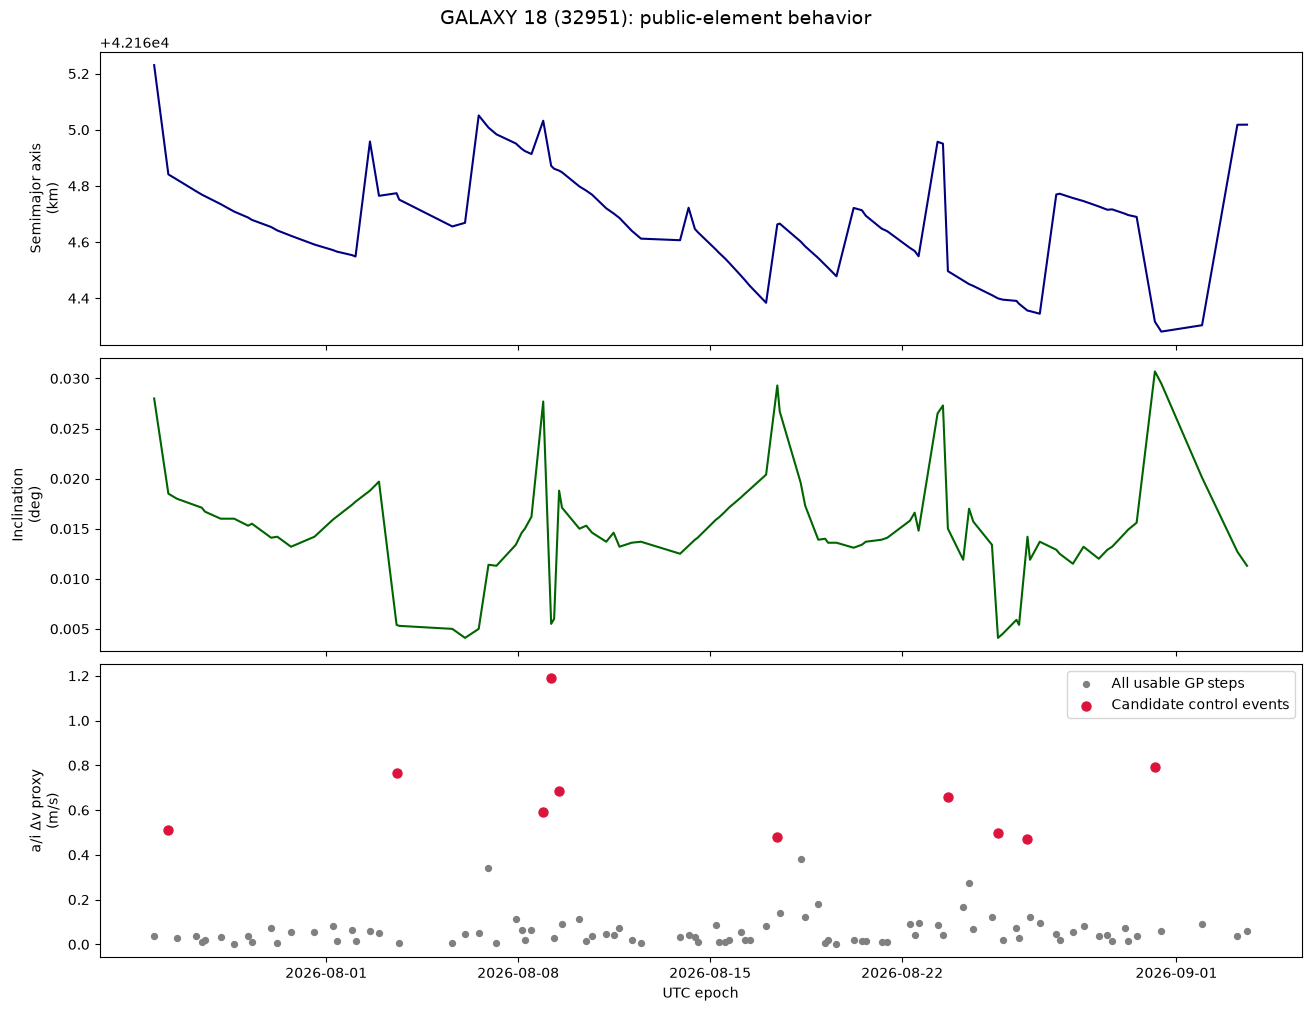

: 

In [ ]:
NORAD_TO_INSPECT = "32951"  # Galaxy 18; replace with any NORAD ID

detail = usable_steps.loc[
    usable_steps["NORAD_CAT_ID"] == NORAD_TO_INSPECT
].copy()

detail_candidates = candidate_steps.loc[
    candidate_steps["NORAD_CAT_ID"] == NORAD_TO_INSPECT
].copy()

if detail.empty:
    raise ValueError(f"No usable steps found for NORAD {NORAD_TO_INSPECT}.")

fig, axes = plt.subplots(
    3,
    1,
    figsize=(13, 10),
    sharex=True,
    constrained_layout=True,
)

axes[0].plot(
    detail["EPOCH"],
    detail["SEMI_MAJOR_AXIS_KM"],
    color="navy",
)
axes[0].set_ylabel("Semimajor axis\n(km)")

axes[1].plot(
    detail["EPOCH"],
    detail["INCLINATION"],
    color="darkgreen",
)
axes[1].set_ylabel("Inclination\n(deg)")

axes[2].scatter(
    detail["EPOCH"],
    detail["AI_DV_PROXY_M_S"],
    color="gray",
    s=18,
    label="All usable GP steps",
)

axes[2].scatter(
    detail_candidates["EPOCH"],
    detail_candidates["AI_DV_PROXY_M_S"],
    color="crimson",
    s=42,
    label="Candidate control events",
)

axes[2].set_ylabel("a/i Δv proxy\n(m/s)")
axes[2].set_xlabel("UTC epoch")
axes[2].legend()

fig.suptitle(
    f"{detail['OBJECT_NAME'].iloc[0]} ({NORAD_TO_INSPECT}): "
    "public-element behavior",
    fontsize=14,
)

plt.show()